In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import os
print('imported')

imported


In [2]:
# set the path
data_dir = r'C:\Users\chand\Downloads\Flowers Recognition\flowers'

In [3]:
# load the dataset
img_size = (224, 224)
batch_size = 32
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.


In [4]:
# check class names
class_names = train_ds.class_names
print(class_names)

['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


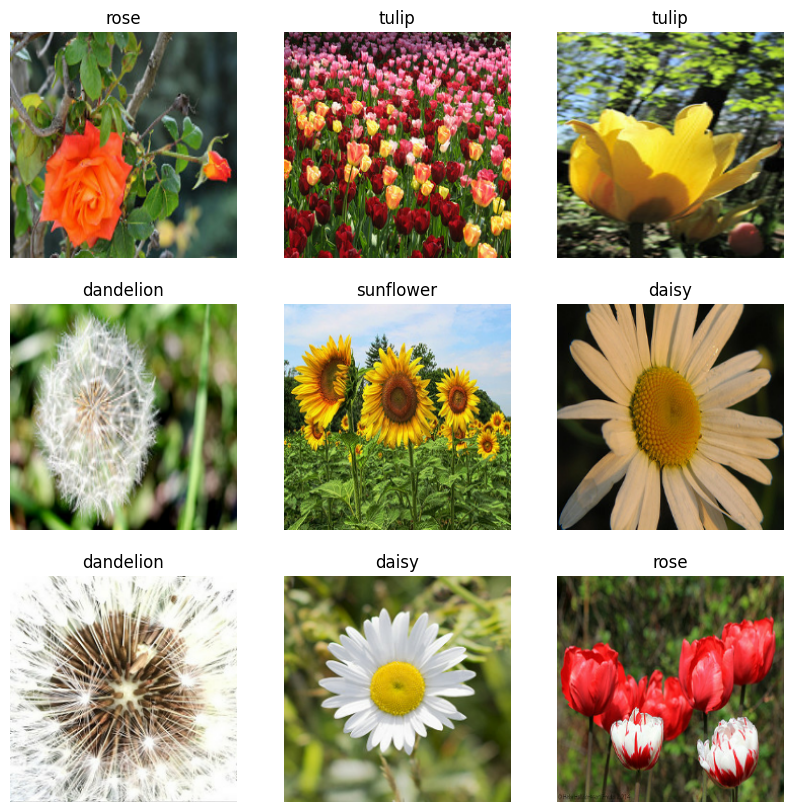

In [5]:
# visualize data
plt.figure(figsize=(10,10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [6]:
# Normalize the data
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

In [7]:
# Improve performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [8]:
# Data Augumentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [9]:
# Build CNN model
model = keras.Sequential([
    data_augmentation,
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(5, activation='softmax')  
])

In [10]:
# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
# train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 310s 3s/step - accuracy: 0.4482 - loss: 1.3057 - val_accuracy: 0.5759 - val_loss: 1.0707
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 391s 4s/step - accuracy: 0.5863 - loss: 1.0265 - val_accuracy: 0.6037 - val_loss: 1.0014
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 427s 3s/step - accuracy: 0.6317 - loss: 0.9453 - val_accuracy: 0.6721 - val_loss: 0.8519
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 343s 3s/step - accuracy: 0.6705 - loss: 0.8608 - val_accuracy: 0.6651 - val_loss: 0.8842
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 352s 3s/step - accuracy: 0.6977 - loss: 0.8105 - val_accuracy: 0.6825 - val_loss: 0.7967
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 352s 3s/step - accuracy: 0.7148 - loss: 0.7569 - val_accuracy: 0.6883 - val_loss: 0.7767
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 329s 3s/step - accuracy: 0.7169 - loss: 0.7344 - val_accuracy: 0.6837 - val_loss: 0.8009
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 345s 3s/step - accuracy: 0.7319 - loss: 0.7098 - val_accu

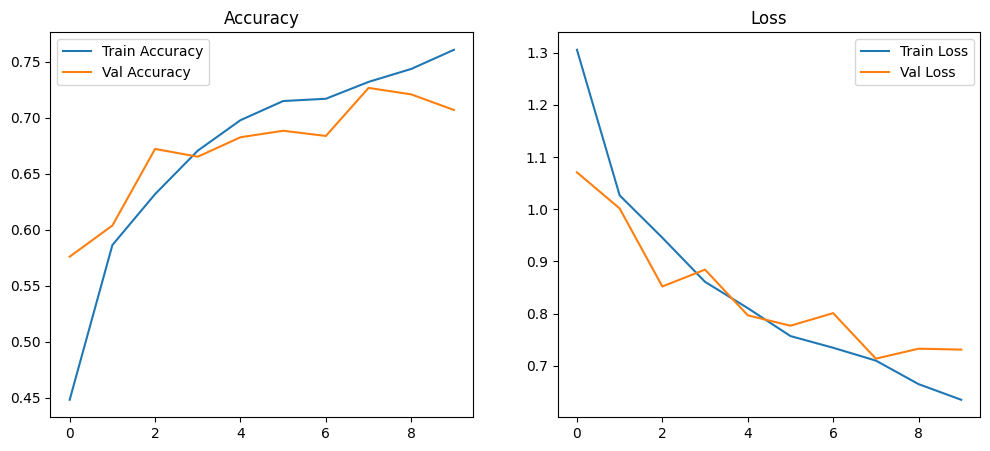

In [12]:
# plot the accuracy and loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.legend()
plt.title("Accuracy")
plt.subplot(1,2,2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.legend()
plt.title("Loss")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 716ms/step


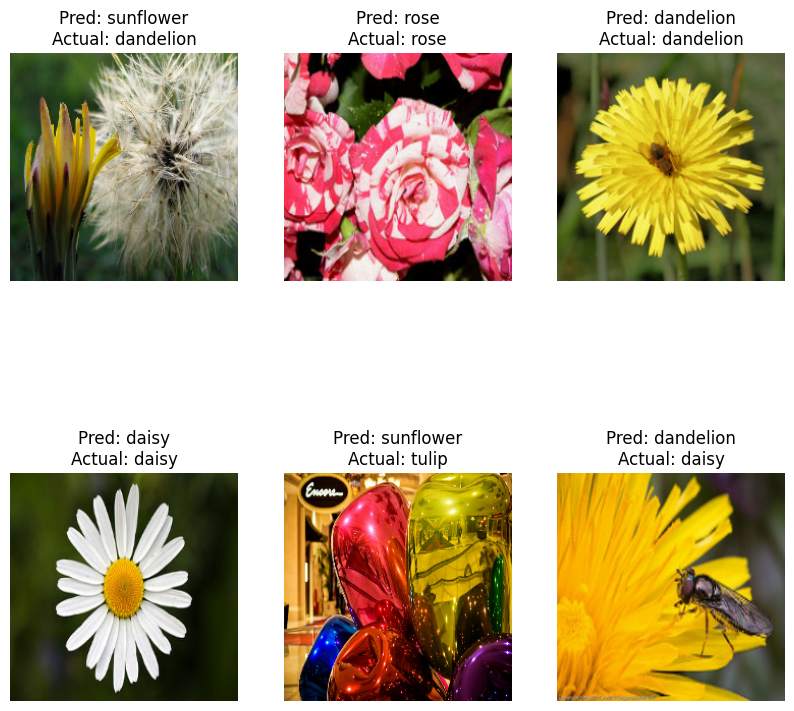

In [13]:
# Test Prediction
for images, labels in val_ds.take(1):
    predictions = model.predict(images)   
    plt.figure(figsize=(10,10))   
    for i in range(6):
        ax = plt.subplot(2,3,i+1)        
        img = images[i].numpy()
        pred_class = np.argmax(predictions[i])
        actual_class = labels[i].numpy()      
        plt.imshow(img.astype("float32"))
        plt.title(f"Pred: {class_names[pred_class]}\nActual: {class_names[actual_class]}")
        plt.axis("off")

    plt.show()